<img src="../../shared/alchemi-banner-left.png" alt="NVIDIA ALCHEMI: AI for Chemistry and Materials Science" style="display:block;box-sizing:border-box;width:100%;max-width:100%;height:auto;">

<style>
h1 { font-size:2.35rem !important; line-height:1.15 !important; margin:0.7rem 0 1rem !important; }
h2 { font-size:1.9rem !important; line-height:1.2 !important; margin:1.8rem 0 0.8rem !important; }
h3 { font-size:1.35rem !important; line-height:1.3 !important; margin:1.5rem 0 0.7rem !important; }
</style>

# ALCHEMI Core · Module 00: Toolkit in your research

**Goal:** See how Toolkit connects chemical systems, models, simulation controls, and execution scale before opening each part of the workflow.

**5–10 minutes**   ·   Next → [Module 1: Batch data](alchemi-core-01-data-and-batching.ipynb)

<img src="assets/course-roadmap.svg?v=20260820j" alt="ALCHEMI Core roadmap" style="display:block;box-sizing:border-box;width:100%;max-width:920px;height:auto;margin:0;">

**00 · Toolkit in your research** · [01 · Batch data](alchemi-core-01-data-and-batching.ipynb) · [02 · Simulate and compose](alchemi-core-02-models-and-simulation.ipynb)

## See the complete role of Toolkit

You are likely here because your research involves molecules, surfaces, nanomaterials, or another atomistic system. Whether you simulate these systems or study them experimentally, you likely use a collection of tools that do the job, but lose time moving between them. Many great solutions exist and serve their purpose, but the overall workflow often lacks the flexibility of a unified toolkit.

**ALCHEMI Toolkit** was inspired by a common challenge in computational chemistry: structure preparation and data loading often happen on the CPU, while models and simulations run on the GPU. As work passes through each stage, the same atomic data must be transferred, converted, and synchronized.

ALCHEMI Toolkit gives these systems a shared, **GPU-resident** data interface and **accelerated building blocks** that bring **AI models**, physical simulations, and scalable execution into one workflow, supporting your R&D needs, scientific curiosity, and ambitious computational studies.

Let’s see this in action:


In [1]:
import torch
from helpers import core as helpers

In [2]:
helpers.configure_tutorial()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Compute device: {device}")

Compute device: cuda


In [3]:
research_systems = helpers.opening_performance_catalog()
research_picker = helpers.show_structure_explorer(research_systems)
research_picker

VBox(children=(HTML(value='\n<style>\n.cell-output-ipywidget-background:has(.alchemi-picker-f1636f7dfd9b4952b8…

## Relax the selected structures together

Choose up to five systems above, then run the next cell. The preview adds reproducible coordinate noise with a 0.10 Å standard deviation so the relaxation is visible. Toolkit packs the structures into one `Batch`; at every FIRE2 step, MACE evaluates the complete batch in one model call, and the shared player advances every trajectory together.

In [ ]:
relaxation = helpers.relax_selected_structures(
    research_picker,
    device=device,
    steps=60 if device.type == "cuda" else 4,
    distortion_std_angstrom=0.10,
    distortion_seed=7,
)
relaxation["player"]

## Put the trajectory time in perspective

The chart keeps the selected trajectory workload fixed and projects DFT time at 1,000× the measured Toolkit time.

> **Toolkit mode**  
> Many structures → 1 GPU
>
> **Conventional DFT simulations**  
> 1 structure → 1 GPU  
> N systems → N nodes


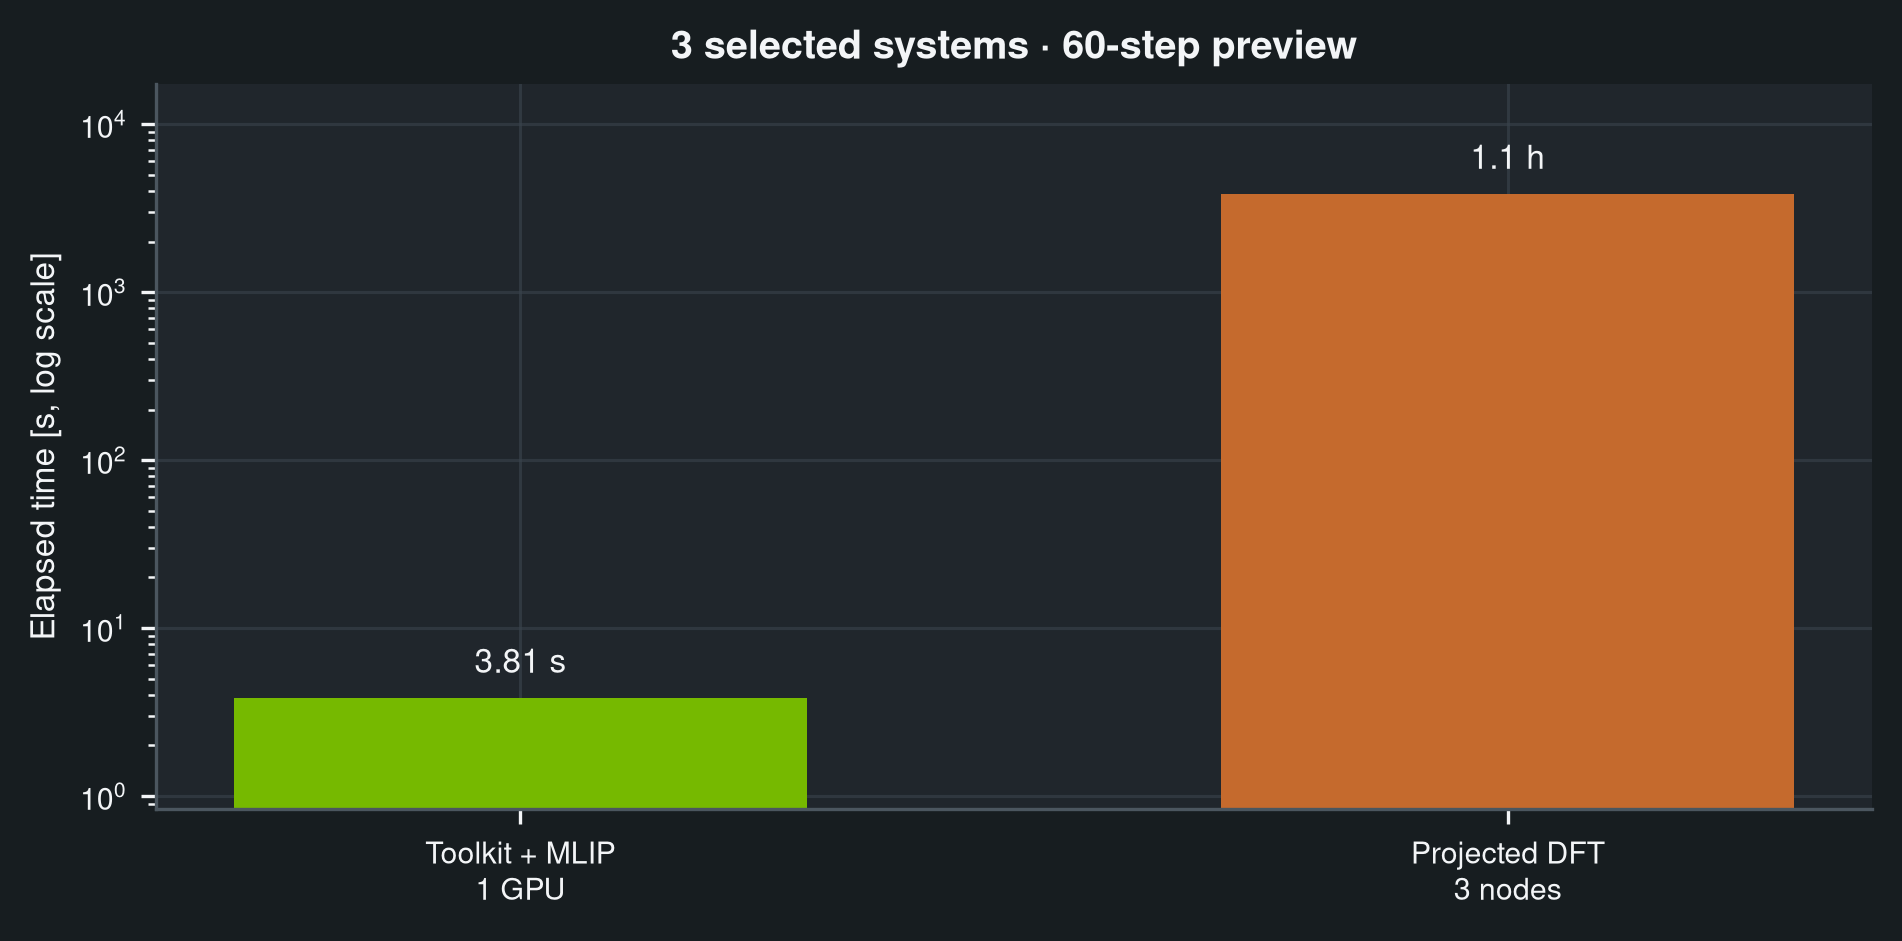

In [ ]:
helpers.plot_relaxation_time_perspective(relaxation)

## Follow the idea into the course

The preview connected the complete path:

`structures → AtomicData → Batch → model → FIRE2 → synchronized trajectories`

The next modules open that path one layer at a time. Module 1 shows how different systems become one packed `Batch`. Module 2 changes models, physical terms, hooks, and dynamics. Module 3 keeps larger workloads moving through stages and across devices.

<hr class="alchemi-section-divider" aria-hidden="true" style="border:0;border-top:1px solid #D6D9D4;margin:2.4rem 0 1rem;">

## What's inside NVIDIA ALCHEMI

[ALCHEMI](https://developer.nvidia.com/cuda/cuda-x-libraries/alchemi) brings together reusable Python tools, accelerated atomistic operations, and deployable services.

- **ALCHEMI Toolkit** is a s a GPU-first Python framework for AI atomic simulations. Run batched molecular dynamics (MD) and relaxation, train or fine-tune machine-learned interatomic potentials (MLIPs), and scale the same composable workflows from one GPU to multi-GPU systems.
  📦 [Repository](https://github.com/NVIDIA/nvalchemi-toolkit) · [Docs](https://nvidia.github.io/nvalchemi-toolkit/) · Apache 2.0

- **Toolkit-Ops** goes one level deeper and provides accleerated batched operations for neighbor lists, dynamics andinteractions such as dispersion, and electrostatics.
  📦 [Repository](https://github.com/NVIDIA/nvalchemi-toolkit-ops) · [Docs](https://nvidia.github.io/nvalchemi-toolkit-ops/) · Apache 2.0

- **ALCHEMI NIM microservices** package supported workflows such as batched geometry relaxation and batched molecular dynamics as deployable services.  
  📘 [Transparency card](https://docs.nvidia.com/nim/alchemi/alchemi-bgr/1.0.0/ai-transparency-card/overview.html) · [Docs](https://docs.nvidia.com/nim/alchemi/alchemi-bgr/latest/index.html) · NVIDIA AI Enterprise



**★ Featured: [Agentic AI workflows with ALCHEMI NIM](https://developer.nvidia.com/blog/faster-chemistry-and-materials-discovery-with-ai-powered-simulations-using-nvidia-alchemi/)**  
See how high-throughput asynchronous simulations support agent-driven discovery loops.

NVIDIA blogs: [Build custom workflows with Toolkit](https://developer.nvidia.com/blog/building-custom-atomistic-simulation-workflows-for-chemistry-and-materials-science-with-nvidia-alchemi-toolkit/) · [Accelerate simulations with Toolkit-Ops](https://developer.nvidia.com/blog/accelerating-ai-powered-chemistry-and-materials-science-simulations-with-nvidia-alchemi-toolkit-ops/)

## Continue

You have seen Toolkit's role across the workflow. [Module 1 begins with one structure, opens its `AtomicData`, and builds a packed `Batch` →](alchemi-core-01-data-and-batching.ipynb)